In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r"C:\Users\Patha\Downloads\customers.csv")

In [4]:
df.head()

,CustomerID,Age,Annual Income,Spending Score
0,C0001,23,87726,92
1,C0002,26,18860,28
2,C0003,41,61435,100
3,C0004,38,111119,74
4,C0005,33,121280,81


In [5]:
features = ['Age','Annual Income' ,'Spending Score']

In [6]:
X = df[features].dropna()
X

,Age,Annual Income,Spending Score
0,23,87726,92
1,26,18860,28
2,41,61435,100
3,38,111119,74
4,33,121280,81
...,...,...,...
495,39,46183,74
496,19,21473,29
497,44,109462,62
498,39,103588,24


In [7]:
# scaling the data using StandardScaler range -3 to 3 ho jaata hai 

from sklearn.preprocessing import StandardScaler


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
X_scaled

array([[-1.07317116,  0.35173686,  1.34489473],
       [-0.81712587, -1.51561367, -0.9570218 ],
       [ 0.46310058, -0.36116229,  1.6326343 ],
       ...,
       [ 0.71914587,  0.94112395,  0.26587136],
       [ 0.29240372,  0.78184627, -1.10089158],
       [ 1.23123645,  1.60394038, -0.41751011]], shape=(500, 3))

In [10]:
from sklearn.cluster import KMeans

In [11]:
wcss=[]
k_values=range(1,11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        random_state=1
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

Text(0, 0.5, 'WCSS')

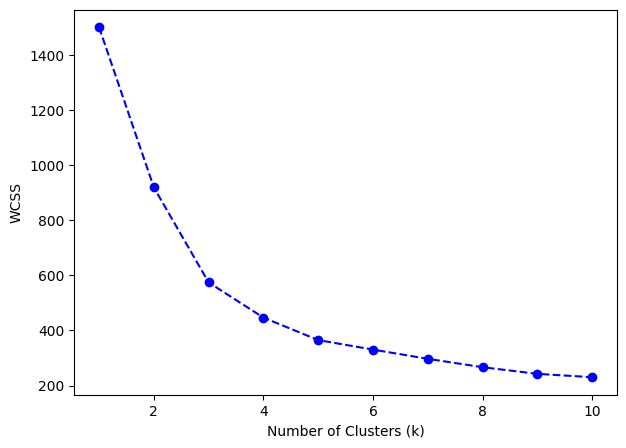

In [12]:
plt.figure(figsize=(7,5))
plt.plot(k_values,wcss,marker='o' ,linestyle='--',color='b')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')

In [13]:
#fit the model with the optimal number of clusters (k=4)

optimal_k = 4
final_model = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    n_init=10,
    random_state=1
)

In [14]:
labels = final_model.fit_predict(X_scaled)

In [15]:
labels #0,1,2,3

array([1, 2, 0, 0, 0, 2, 3, 0, 0, 0, 1, 1, 2, 0, 2, 2, 1, 0, 1, 2, 2, 0,
       1, 2, 3, 0, 3, 1, 2, 2, 0, 0, 1, 1, 1, 2, 2, 2, 2, 0, 3, 1, 0, 3,
       1, 0, 1, 3, 2, 3, 1, 3, 2, 0, 3, 2, 2, 1, 0, 0, 0, 0, 0, 2, 1, 3,
       0, 1, 2, 2, 0, 2, 1, 1, 1, 2, 1, 1, 1, 2, 0, 1, 0, 0, 2, 0, 2, 1,
       3, 1, 3, 1, 3, 2, 3, 1, 1, 1, 2, 2, 0, 3, 3, 0, 2, 0, 3, 3, 3, 0,
       0, 3, 0, 2, 3, 2, 3, 3, 2, 2, 0, 3, 1, 2, 2, 3, 3, 0, 1, 1, 2, 1,
       1, 1, 1, 2, 2, 2, 0, 2, 0, 2, 3, 1, 0, 1, 0, 3, 1, 2, 1, 3, 2, 2,
       1, 0, 2, 0, 1, 0, 3, 2, 3, 0, 2, 3, 2, 2, 0, 3, 1, 1, 0, 1, 0, 0,
       0, 1, 3, 2, 1, 2, 0, 2, 0, 0, 2, 3, 1, 1, 1, 0, 1, 1, 3, 0, 3, 2,
       0, 0, 1, 2, 1, 2, 0, 2, 0, 1, 2, 1, 2, 1, 2, 2, 2, 1, 2, 3, 0, 0,
       3, 0, 2, 3, 2, 3, 3, 0, 2, 1, 2, 0, 1, 1, 2, 2, 0, 3, 2, 3, 2, 2,
       3, 0, 2, 1, 3, 2, 0, 2, 3, 1, 0, 2, 0, 1, 3, 3, 2, 1, 3, 2, 1, 1,
       2, 3, 0, 0, 2, 0, 2, 1, 1, 1, 2, 1, 2, 2, 2, 0, 1, 1, 2, 0, 0, 3,
       3, 0, 2, 1, 3, 1, 2, 2, 2, 3, 3, 3, 2, 1, 1,

In [16]:
df_clustered = df.loc[X.index].copy()
df_clustered['Cluster'] = labels

In [17]:
df_clustered.head()

,CustomerID,Age,Annual Income,Spending Score,Cluster
0,C0001,23,87726,92,1
1,C0002,26,18860,28,2
2,C0003,41,61435,100,0
3,C0004,38,111119,74,0
4,C0005,33,121280,81,0


In [ ]:
#silhouette score - to evaluate the quality of clustering --jitna zyada score hoga utna acha clustering hoga

from sklearn.metrics import silhouette_score 

In [19]:
silhouette_score(X_scaled, labels)

0.36679324725475076

Text(0.5, 1.0, 'Customer Segmentation using K-Means Clustering')

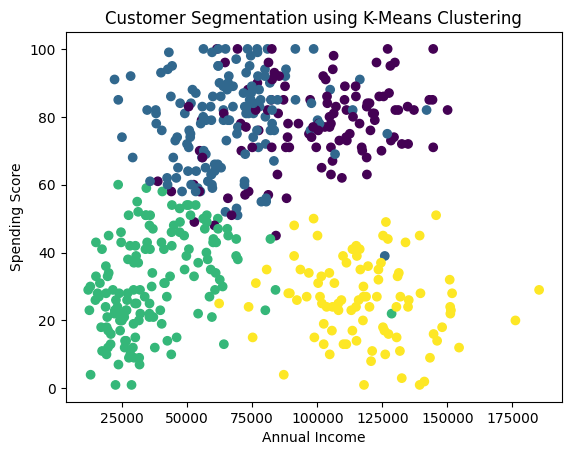

In [29]:
#plotting the clusters to understand the distribution of clusters
df_clustered.groupby('Cluster')[features].mean()

plt.scatter(df_clustered['Annual Income'], df_clustered['Spending Score'], c=df_clustered['Cluster'], cmap='viridis')

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation using K-Means Clustering')